# 03 · Item-based collaborative filtering

1. Build the user × movie matrix $R$ (943 × 1682) from the training ratings.
2. Cosine similarity between movie columns: $\mathrm{sim}(i,j) = \dfrac{r_{\cdot i}\cdot r_{\cdot j}}{\lVert r_{\cdot i}\rVert\,\lVert r_{\cdot j}\rVert}$ (optionally after subtracting each user's mean — *adjusted cosine*).
3. Keep the $k$ nearest neighbours of each movie.
4. **Ranking:** $s(u,i) = \sum_{j \in I_u} \mathrm{sim}(i,j)\,w_{uj}$, with $w_{uj}=1$ or $w_{uj}=r_{uj}$.
5. **Rating prediction:** $\hat r_{ui} = \bar r_u + \dfrac{\sum_{j \in N_k(i;u)} \mathrm{sim}(i,j)(r_{uj}-\bar r_u)}{\sum_{j} |\mathrm{sim}(i,j)|}$ over the $k$ most similar movies that $u$ rated.

In [1]:
import sys, json
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 4); pd.set_option("display.width", 140)
RESULTS = Path("../results"); RESULTS.mkdir(exist_ok=True)

def save_params(name, params):
    path = RESULTS / "best_params.json"
    allp = json.loads(path.read_text()) if path.exists() else {}
    allp[name] = {k: (v.item() if hasattr(v, "item") else v) for k, v in params.items()}
    path.write_text(json.dumps(allp, indent=2))

In [2]:
from src.data import load_ratings, load_movies, temporal_user_split
ratings, movies = load_ratings(), load_movies()
train, test = temporal_user_split(ratings, test_frac=0.2)
train_in, valid = temporal_user_split(train, test_frac=0.2)
title = movies.set_index("item_idx")["title"]
print(f"train={len(train)} test={len(test)} | train_in={len(train_in)} valid={len(valid)}")

train=80000 test=20000 | train_in=64005 valid=15995


In [3]:
from src.models import ItemKNNRecommender, user_item_matrix
from src.evaluation import grid_search, evaluate_ranking, evaluate_rmse, recommend_top_k
R = user_item_matrix(train)
print("user-item matrix:", R.shape, f"non-zeros={R.nnz}, density={R.nnz / np.prod(R.shape):.3%}")
knn = ItemKNNRecommender(k=50).fit(train)

user-item matrix: (943, 1682) non-zeros=80000, density=5.044%


## Similar movies (cosine on the training matrix)

In [4]:
def show_similar(model, item_id, n=8):
    idx, sims = model.similar_items(item_id - 1, n)
    return pd.DataFrame({"similar movie": title[idx].values, "cosine": sims})

for item_id in [50, 1, 98]:
    print("\n==", title[item_id - 1]); print(show_similar(knn, item_id).to_string(index=False))


== Star Wars (1977)
                   similar movie  cosine
       Return of the Jedi (1983)  0.8447
 Empire Strikes Back, The (1980)  0.7000
                Toy Story (1995)  0.6991
  Raiders of the Lost Ark (1981)  0.6987
           Godfather, The (1972)  0.6578
                    Fargo (1996)  0.6406
Silence of the Lambs, The (1991)  0.6385
   Independence Day (ID4) (1996)  0.6317

== Toy Story (1995)
                  similar movie  cosine
               Star Wars (1977)  0.6991
      Return of the Jedi (1983)  0.6709
  Independence Day (ID4) (1996)  0.6410
               Rock, The (1996)  0.6199
           Jerry Maguire (1996)  0.6080
                   Fargo (1996)  0.5919
Star Trek: First Contact (1996)  0.5816
     Mission: Impossible (1996)  0.5792

== Silence of the Lambs, The (1991)
                  similar movie  cosine
            Pulp Fiction (1994)  0.7145
 Raiders of the Lost Ark (1981)  0.6991
Empire Strikes Back, The (1980)  0.6922
            Forrest Gump (1994) 

## Hyper-parameter selection on the validation split

In [5]:
grid_rank = grid_search(ItemKNNRecommender,
                        {"k": [10, 20, 50, 100, 200, 1682], "centered": [False, True],
                         "weighting": ["binary", "rating"]},
                        train_in, valid, objective="ndcg@10", verbose=False)
grid_rank.head(10)

,k,centered,weighting,precision@10,recall@10,ndcg@10,coverage@10
0,1682,False,rating,0.1130,0.1723,0.1688,0.1136
1,1682,False,binary,0.1110,0.1720,0.1662,0.1165
2,100,False,rating,0.1082,0.1736,0.1654,0.2081
3,200,False,rating,0.1093,0.1682,0.1636,0.1819
4,50,False,rating,0.1092,0.1673,0.1608,0.2319
5,200,False,binary,0.1064,0.1664,0.1590,0.1837
6,20,False,rating,0.1059,0.1625,0.1581,0.2551
7,100,False,binary,0.1048,0.1684,0.1579,0.2099
8,10,False,rating,0.1013,0.1625,0.1547,0.2580
9,50,False,binary,0.1011,0.1592,0.1511,0.2348


In [6]:
grid_rmse = grid_search(lambda k, centered: ItemKNNRecommender(k=k, centered=centered),
                        {"k": [10, 20, 50, 100, 200], "centered": [False, True]},
                        train_in, valid, objective="rmse", verbose=False)
grid_rmse

,k,centered,rmse
0,20,True,0.9981
1,50,True,1.0005
2,100,True,1.0019
3,200,True,1.0020
4,10,True,1.0058
5,10,False,1.0343
6,20,False,1.0366
7,50,False,1.0479
8,100,False,1.0543
9,200,False,1.0565


In [7]:
best_rank = grid_rank.iloc[0][["k", "centered", "weighting"]].to_dict()
best_rmse = grid_rmse.iloc[0][["k", "centered"]].to_dict()
save_params("itemknn_ranking", best_rank); save_params("itemknn_rating", best_rmse)
grid_rank.to_csv(RESULTS / "grid_itemknn_ranking.csv", index=False)
grid_rmse.to_csv(RESULTS / "grid_itemknn_rmse.csv", index=False)
best_rank, best_rmse

({'k': 1682, 'centered': False, 'weighting': 'rating'},
 {'k': 20, 'centered': True})

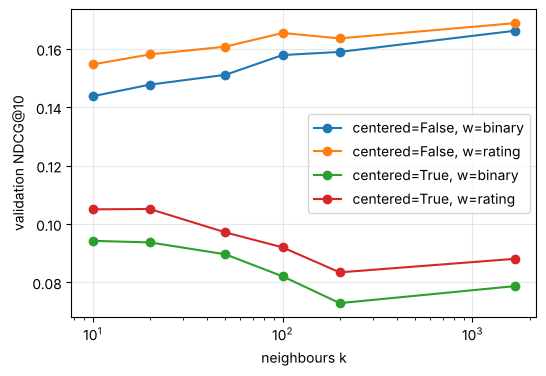

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
for (c, w), g in grid_rank.groupby(["centered", "weighting"]):
    g = g.sort_values("k"); ax.plot(g.k, g["ndcg@10"], marker="o", label=f"centered={c}, w={w}")
ax.set_xscale("log"); ax.set_xlabel("neighbours k"); ax.set_ylabel("validation NDCG@10"); ax.legend(); ax.grid(alpha=.3);

## Recommendations from a user's history

In [9]:
model = ItemKNNRecommender(**best_rank).fit(train)
u = 0
hist = train[train.user_idx == u].sort_values("rating", ascending=False)
print("User", u + 1, "top-rated training movies:"); print(title[hist.item_idx.head(5)].to_string())
rec = recommend_top_k(model, train, [u], 10)[0]
liked = set(test[(test.user_idx == u) & (test.rating >= 4)].item_idx)
pd.DataFrame({"recommendation": title[rec].values, "in test & liked": [i in liked for i in rec]}, index=range(1, 11))

User 1 top-rated training movies:
item_idx
167            Monty Python and the Holy Grail (1974)
171                   Empire Strikes Back, The (1980)
164                           Jean de Florette (1986)
165    Manon of the Spring (Manon des sources) (1986)
195                         Dead Poets Society (1989)


,recommendation,in test & liked
1,E.T. the Extra-Terrestrial (1982),False
2,Fargo (1996),True
3,Star Trek: The Wrath of Khan (1982),True
4,Young Frankenstein (1974),True
5,Stand by Me (1986),False
6,True Lies (1994),False
7,Speed (1994),False
8,Schindler's List (1993),False
9,This Is Spinal Tap (1984),True
10,One Flew Over the Cuckoo's Nest (1975),False


## Test-set performance

In [10]:
rate_model = ItemKNNRecommender(**best_rmse).fit(train)
res = evaluate_ranking(model, train, test, ks=(10,))
res["rmse"] = evaluate_rmse(rate_model, test)
pd.Series(res)

precision@10      0.1221
recall@10         0.1402
ndcg@10           0.1651
coverage@10       0.1266
n_users         906.0000
rmse              1.0215
dtype: float64